# Лабораторна робота № 8 — самостійне моделювання зовнішніх даних

**Номер у списку:** 17. **Варіант:** $(17-1)\bmod 12+1=5$. **Набір:** Real Estate Valuation.

**Мета:** оцінити ціну житла за одиницю площі за відомими на дату угоди характеристиками, порівняти прості моделі з нейромережею та перевірити відтворення прогнозу після збереження.

## Паспорт джерела

| Поле | Значення |
|---|---|
| Джерело | [UCI Machine Learning Repository, Real Estate Valuation](https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set) |
| Автор | I-Cheng Yeh, Tamkang University |
| Цитування | Yeh, I. (2018). *Real Estate Valuation* [Dataset]. UCI Machine Learning Repository. [DOI: 10.24432/C5J30W](https://doi.org/10.24432/C5J30W) |
| Ліцензія | [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) |
| Завантажено | 2026-11-09 з [офіційного XLSX](https://archive.ics.uci.edu/ml/machine-learning-databases/00477/Real%20estate%20valuation%20data%20set.xlsx) |
| Локальний оригінал | `data/Real estate valuation data set.xlsx`, аркуш `工作表1` |
| Обсяг | 414 угод, 6 ознак, ціль та ідентифікатор `No` |
| Що означає рядок | Одна історична угода з нерухомістю в районі Сіньдянь, Новий Тайбей, Тайвань |
| Ціль | `Y house price of unit area`, 10 000 нових тайванських доларів за пінг; 1 пінг ≈ 3,3 м² |

Сирий XLSX збережено без змін. Джерело описує `X1 transaction date` як десятковий запис року та частини року, а не календарний тип datetime.

In [1]:
import json, os, platform, random
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display, Image
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
ROOT = Path('Lab8') if Path('Lab8/data/Real estate valuation data set.xlsx').exists() else Path('.')
DATA = ROOT / 'data' / 'Real estate valuation data set.xlsx'
ART = ROOT / 'artifacts'; FIG = ROOT / 'figures'
ART.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
VERSIONS = {'python': platform.python_version(), 'tensorflow': tf.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'matplotlib': __import__('matplotlib').__version__,
            'openpyxl': __import__('openpyxl').__version__, 'joblib': joblib.__version__}
print('SEED:', SEED, '| версії:', VERSIONS)

Matplotlib is building the font cache; this may take a moment.


/Users/staslulko/Documents/GitHub/data-mining/Lab5/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


SEED: 42 | версії: {'python': '3.9.6', 'tensorflow': '2.16.2', 'numpy': '1.26.4', 'pandas': '2.3.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.9.4', 'openpyxl': '3.1.5', 'joblib': '1.5.3'}


## Постановка задачі й первинна перевірка

За датою угоди, віком будинку, відстанню до найближчої станції MRT, кількістю магазинів поруч і географічними координатами прогнозуємо **ціну за одиницю площі** для об'єкта в районі Сіньдянь **на момент укладання угоди**. Усі ці ознаки відомі на цей момент; `No` є лише номером рядка і не має прогнозного змісту. Ціль — числова величина з осмисленою різницею між значеннями, отже це **регресія**, а не класифікація. Вихід мережі — `Dense(1)` без активації, функція втрат — MSE, критерій вибору — найменший validation RMSE. MAE, RMSE та R² подаються в оцінці; MAE і RMSE мають одиниці цілі.

In [2]:
SHEET = '工作表1'
df = pd.read_excel(DATA, sheet_name=SHEET)
DATE = 'X1 transaction date'; TARGET = 'Y house price of unit area'; ID = 'No'
FEATURES = [c for c in df.columns if c not in (ID, TARGET)]
NUMERIC = FEATURES.copy(); CATEGORICAL = []  # X4 — кількість магазинів, а не код категорії
print('shape:', df.shape, '| sheet:', SHEET)
display(df.head())
display(df.dtypes.rename('dtype').to_frame())
display(df.describe().T)
display(df.isna().sum().rename('missing').to_frame())
print('Точні дублікати всіх полів:', int(df.duplicated().sum()))
print('Точні дублікати без No:', int(df.drop(columns=ID).duplicated().sum()))
print('Розподіл дат угод:')
display(df[DATE].value_counts().sort_index().rename('n').to_frame())
assert df.shape == (414, 8)
assert df[TARGET].notna().all()
assert df[FEATURES].apply(pd.to_numeric, errors='coerce').notna().all().all()

shape: (414, 8) | sheet: 工作表1


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


,dtype
No,int64
X1 transaction date,float64
X2 house age,float64
X3 distance to the nearest MRT station,float64
X4 number of convenience stores,int64
X5 latitude,float64
X6 longitude,float64
Y house price of unit area,float64


,count,mean,std,min,25%,50%,75%,max
No,414.0,207.500000,119.655756,1.000000,104.250000,207.500000,310.750000,414.000000
X1 transaction date,414.0,2013.148953,0.281995,2012.666667,2012.916667,2013.166667,2013.416667,2013.583333
X2 house age,414.0,17.712560,11.392485,0.000000,9.025000,16.100000,28.150000,43.800000
X3 distance to the nearest MRT station,414.0,1083.885689,1262.109595,23.382840,289.324800,492.231300,1454.279000,6488.021000
X4 number of convenience stores,414.0,4.094203,2.945562,0.000000,1.000000,4.000000,6.000000,10.000000
X5 latitude,414.0,24.969030,0.012410,24.932070,24.963000,24.971100,24.977455,25.014590
X6 longitude,414.0,121.533361,0.015347,121.473530,121.528085,121.538630,121.543305,121.566270
Y house price of unit area,414.0,37.980193,13.606488,7.600000,27.700000,38.450000,46.600000,117.500000


,missing
No,0
X1 transaction date,0
X2 house age,0
X3 distance to the nearest MRT station,0
X4 number of convenience stores,0
X5 latitude,0
X6 longitude,0
Y house price of unit area,0


Точні дублікати всіх полів: 0
Точні дублікати без No: 0
Розподіл дат угод:


,n
X1 transaction date,
2012.666667,30
2012.750000,27
2012.833333,31
2012.916667,38
2013.000000,28
2013.083333,46
2013.166667,25
2013.250000,32
2013.333333,29


Пропущених цілей немає. Дублікати перевірено з `No` та без нього; записів не вилучаємо. Усі шість ознак числові за змістом. `X1` використовується і для впорядкування, і як відома на момент угоди ознака; однакові значення дати лишаються в одній вибірці. Майбутні дати в test роблять оцінку перевіркою перенесення на пізніші періоди в межах цього набору.

In [3]:
# Підбираємо межі лише між унікальними датами, мінімізуючи відхилення від 70/15/15.
ordered = df.sort_values(DATE, kind='stable')
counts = ordered.groupby(DATE, sort=True).size().to_numpy()
ends = np.cumsum(counts)
n = len(ordered)
choices = [(abs(ends[i]/n-.70) + abs((ends[j]-ends[i])/n-.15) + abs((n-ends[j])/n-.15), i, j)
           for i in range(len(ends)-2) for j in range(i+1, len(ends)-1)]
_, i, j = min(choices)
idx_train = ordered.index[:ends[i]].to_numpy()
idx_val = ordered.index[ends[i]:ends[j]].to_numpy()
idx_test = ordered.index[ends[j]:].to_numpy()
assert not (set(idx_train)&set(idx_val) or set(idx_train)&set(idx_test) or set(idx_val)&set(idx_test))
assert len(idx_train)+len(idx_val)+len(idx_test)==len(df)
splits = {'train': idx_train, 'validation': idx_val, 'test': idx_test}
for name, idx in splits.items():
    part = df.loc[idx]
    print(f'{name}: n={len(idx)}, date=[{part[DATE].min():.6f}, {part[DATE].max():.6f}]')
assert df.loc[idx_train, DATE].max() < df.loc[idx_val, DATE].min()
assert df.loc[idx_val, DATE].max() < df.loc[idx_test, DATE].min()
X = df[FEATURES]; y = df[TARGET].astype(float)
X_train, X_val, X_test = (X.loc[idx] for idx in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (y.loc[idx].to_numpy() for idx in (idx_train, idx_val, idx_test))

train: n=286, date=[2012.666667, 2013.333333]
validation: n=58, date=[2013.416667, 2013.416667]
test: n=70, date=[2013.500000, 2013.583333]


## Підготовка ознак

Медіана та параметри стандартизації оцінюються **лише за train**. Категоріальних ознак у цьому варіанті немає, тому відповідна гілка `ColumnTransformer` не потрібна. Вихід препроцесора переводимо в `float32` для Keras. Ціль лишається у вихідних одиницях і має форму `(N, 1)` під час навчання мережі.

In [4]:
transformers = [('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                                  ('scaler', StandardScaler())]), NUMERIC)]
if CATEGORICAL:
    transformers.append(('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CATEGORICAL))
preprocessor = ColumnTransformer(transformers, remainder='drop')
Z_train = preprocessor.fit_transform(X_train).astype('float32')
Z_val = preprocessor.transform(X_val).astype('float32')
Z_test = preprocessor.transform(X_test).astype('float32')
for arr in (Z_train, Z_val, Z_test):
    assert np.isfinite(arr).all() and arr.shape[1] == Z_train.shape[1]
assert X_train.columns.tolist() == X_val.columns.tolist() == X_test.columns.tolist() == FEATURES
print('Порядок ознак:', FEATURES, '| після підготовки:', Z_train.shape[1])

Порядок ознак: ['X1 transaction date', 'X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude'] | після підготовки: 6


## Чотири моделі та критерій вибору

Dummy прогнозує середнє train, LinearRegression є класичним орієнтиром. NN_base має два шари по 32 ReLU-нейрони, Adam(0.001), batch size 64, не більш як 200 епох, EarlyStopping з patience 15 та окремий checkpoint найкращого `val_loss`. Мінімум MSE дорівнює мінімуму RMSE для тієї самої validation-вибірки. Усі моделі використовують однаковий препроцесор і поділ. Test відкриваємо лише після вибору за validation.

In [5]:
def metrics(y_true, pred):
    return {'MAE': mean_absolute_error(y_true, pred),
            'RMSE': root_mean_squared_error(y_true, pred),
            'R2': r2_score(y_true, pred)}

dummy = DummyRegressor(strategy='mean').fit(Z_train, y_train)
linear = LinearRegression().fit(Z_train, y_train)
val_predictions = {'Dummy': dummy.predict(Z_val), 'LinearRegression': linear.predict(Z_val)}

def build_nn(learning_rate=0.001):
    return keras.Sequential([layers.Input(shape=(Z_train.shape[1],)),
                             layers.Dense(32, activation='relu'),
                             layers.Dense(32, activation='relu'),
                             layers.Dense(1)], name='real_estate_regressor')

def fit_nn(name, learning_rate):
    tf.keras.utils.set_random_seed(SEED)
    model = build_nn(learning_rate)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss='mse',
                  metrics=[keras.metrics.RootMeanSquaredError(name='rmse')])
    checkpoint = ART / f'{name}_best.keras'
    history = model.fit(Z_train, y_train.reshape(-1,1).astype('float32'),
                        validation_data=(Z_val, y_val.reshape(-1,1).astype('float32')),
                        epochs=200, batch_size=64, verbose=0,
                        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15),
                                   keras.callbacks.ModelCheckpoint(checkpoint, monitor='val_loss',
                                                                    save_best_only=True)])
    best_epoch = int(np.argmin(history.history['val_loss']) + 1)
    best = keras.models.load_model(checkpoint)
    return best, history.history, best_epoch

base, hist_base, epoch_base = fit_nn('NN_base', 0.001)
val_predictions['NN_base'] = base.predict(Z_val, verbose=0).ravel()
print('NN_base: виконано', len(hist_base['loss']), 'епох; checkpoint:', epoch_base)
print('validation:', metrics(y_val, val_predictions['NN_base']))

NN_base: виконано 55 епох; checkpoint: 40
validation: {'MAE': 6.430446647775585, 'RMSE': 7.7566614408930405, 'R2': 0.557263420492264}


## Гіпотеза покращення

Крива базової мережі показує мінімум validation RMSE на 40-й епосі, після чого validation-помилка зростає, хоча train-помилка ще спадає. Перевіряємо **одну зміну**: зменшуємо learning rate Adam з 0.001 до 0.0003, лишаючи архітектуру, дані, batch size і callbacks незмінними. Менший крок може дозволити точніше наблизитися до мінімуму, хоча вимагатиме більше епох. Успіх визначає лише фактичний validation RMSE.

In [6]:
improved, hist_improved, epoch_improved = fit_nn('NN_improved', 0.0003)
val_predictions['NN_improved'] = improved.predict(Z_val, verbose=0).ravel()
val_rows = []
for name, pred in val_predictions.items():
    row = {'model': name, **metrics(y_val, pred)}
    row['change'] = 'Adam LR 0.0003' if name == 'NN_improved' else ('Adam LR 0.001' if name == 'NN_base' else '—')
    row['epochs_run'] = len(hist_base['loss']) if name == 'NN_base' else (len(hist_improved['loss']) if name == 'NN_improved' else None)
    row['best_epoch'] = epoch_base if name == 'NN_base' else (epoch_improved if name == 'NN_improved' else None)
    val_rows.append(row)
validation = pd.DataFrame(val_rows).set_index('model')
display(validation)
best_nn_name = min(['NN_base','NN_improved'], key=lambda name: (validation.loc[name,'RMSE'], name != 'NN_base'))
best_overall = validation['RMSE'].idxmin()
print('Найкраща мережа:', best_nn_name, '| найкраща модель загалом:', best_overall)
print('Зміна validation RMSE improved - base:', round(validation.loc['NN_improved','RMSE'] - validation.loc['NN_base','RMSE'],4))

,MAE,RMSE,R2,change,epochs_run,best_epoch
model,,,,,,
Dummy,9.406499,11.679791,-0.003843,—,NaN,NaN
LinearRegression,6.097237,7.592023,0.575859,—,NaN,NaN
NN_base,6.430447,7.756661,0.557263,Adam LR 0.001,55.0,40.0
NN_improved,6.371872,7.611167,0.573717,Adam LR 0.0003,146.0,131.0


Найкраща мережа: NN_improved | найкраща модель загалом: LinearRegression
Зміна validation RMSE improved - base: -0.1455


## Фінальна оцінка на test

Після фіксації вибору вище test використовується **один раз** для чотирьох моделей. Метрики обчислюємо в одиницях оригінальної цілі. Налаштування за test не змінюємо.

In [7]:
models = {'Dummy': dummy, 'LinearRegression': linear, 'NN_base': base, 'NN_improved': improved}
test_predictions = {}
for name, model in models.items():
    pred = model.predict(Z_test, verbose=0).ravel() if name.startswith('NN') else model.predict(Z_test)
    test_predictions[name] = pred
comparison = validation.rename(columns={'MAE':'validation_MAE','RMSE':'validation_RMSE','R2':'validation_R2'}).copy()
for name, pred in test_predictions.items():
    comparison.loc[name, ['test_MAE','test_RMSE','test_R2']] = list(metrics(y_test,pred).values())
comparison.insert(0, 'validation_criterion', 'min RMSE')
comparison['selected_nn'] = comparison.index == best_nn_name
comparison['selected_overall'] = comparison.index == best_overall
comparison.to_csv(ROOT / 'model_comparison.csv', index_label='model')
pred_table = df.loc[idx_test, [ID, DATE] + FEATURES[1:] + [TARGET]].copy()
pred_table.insert(0, 'source_index', idx_test)
for name, pred in test_predictions.items(): pred_table[f'prediction_{name}'] = pred
pred_table['residual_selected_nn'] = y_test-test_predictions[best_nn_name]
pred_table.to_csv(ROOT / 'test_predictions.csv', index=False)
display(comparison)
print('Збережено model_comparison.csv і test_predictions.csv')

,validation_criterion,validation_MAE,validation_RMSE,validation_R2,change,epochs_run,best_epoch,test_MAE,test_RMSE,test_R2,selected_nn,selected_overall
model,,,,,,,,,,,,
Dummy,min RMSE,9.406499,11.679791,-0.003843,—,NaN,NaN,12.057692,14.404468,-0.003715,False,False
LinearRegression,min RMSE,6.097237,7.592023,0.575859,—,NaN,NaN,7.510653,9.493551,0.564013,False,True
NN_base,min RMSE,6.430447,7.756661,0.557263,Adam LR 0.001,55.0,40.0,7.358753,9.347976,0.577281,False,False
NN_improved,min RMSE,6.371872,7.611167,0.573717,Adam LR 0.0003,146.0,131.0,7.391625,9.332010,0.578724,True,False


Збережено model_comparison.csv і test_predictions.csv


## Графіки

Перший рисунок описує лише train. Другий порівнює динаміку обох мереж та позначає епоху checkpoint. Останні два рисунки використовують test-прогнози **мережі, обраної за validation**. Усі значення цілі в одиницях 10 000 TWD/пінг.

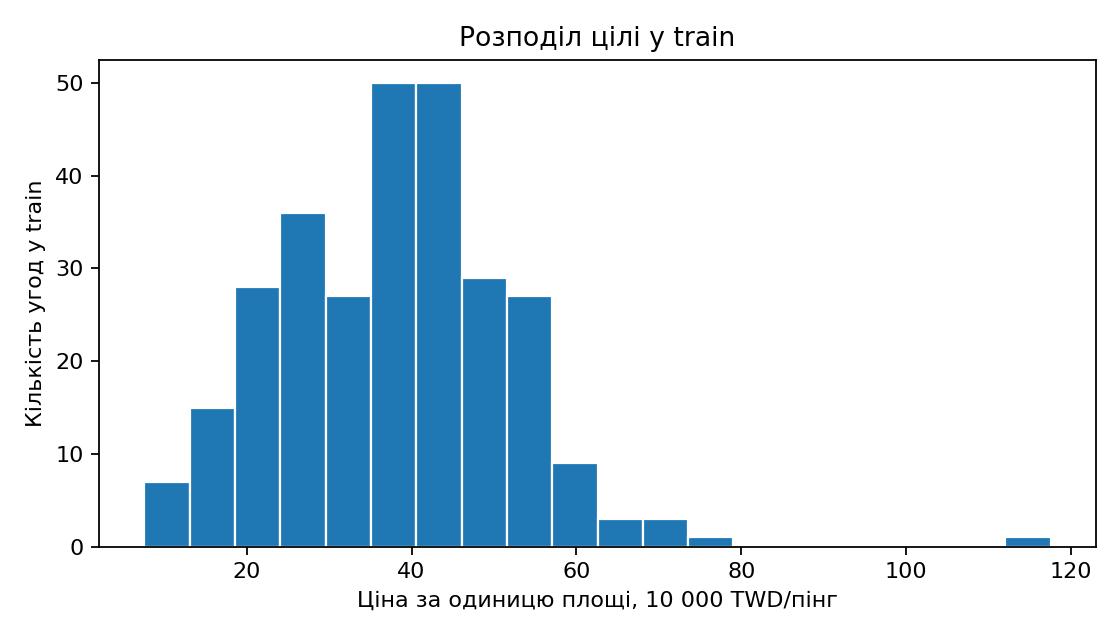

Інтерпретація: більшість train-угод зосереджена в центральному діапазоні ціни; крайні значення трапляються рідше.


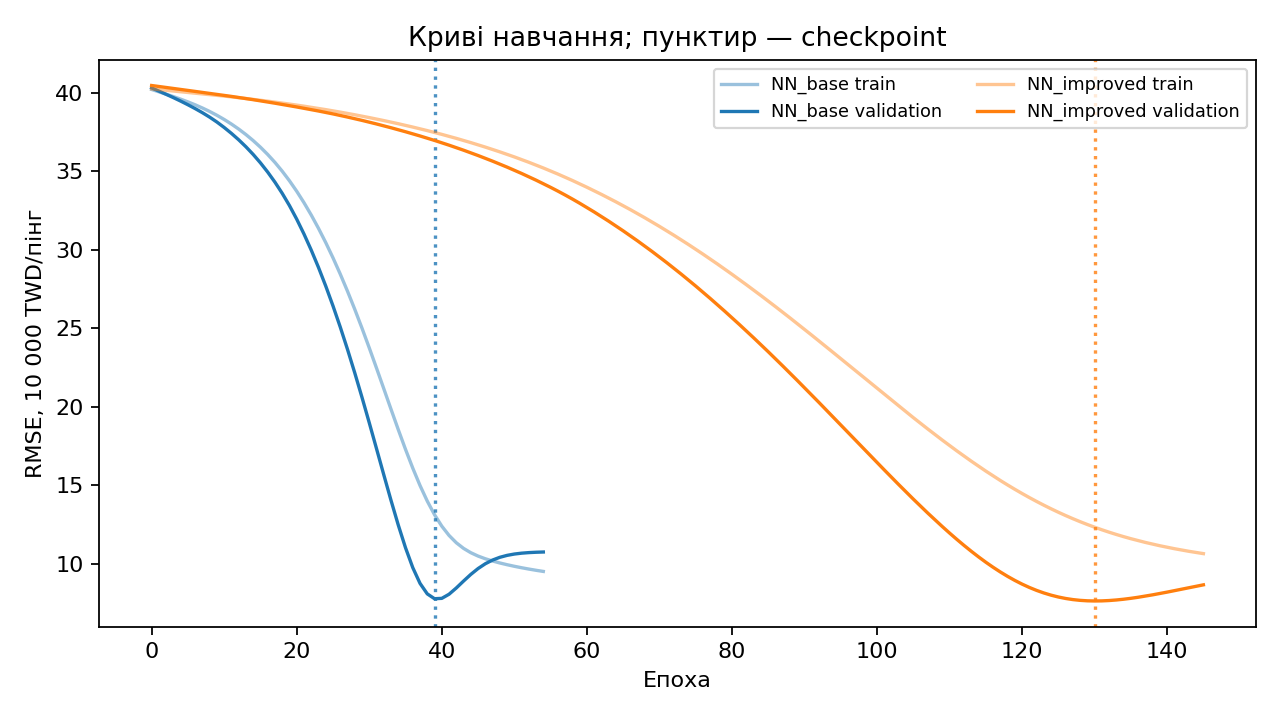

Інтерпретація: checkpoint base — епоха 40, improved — 131; validation RMSE 7.76 → 7.61.


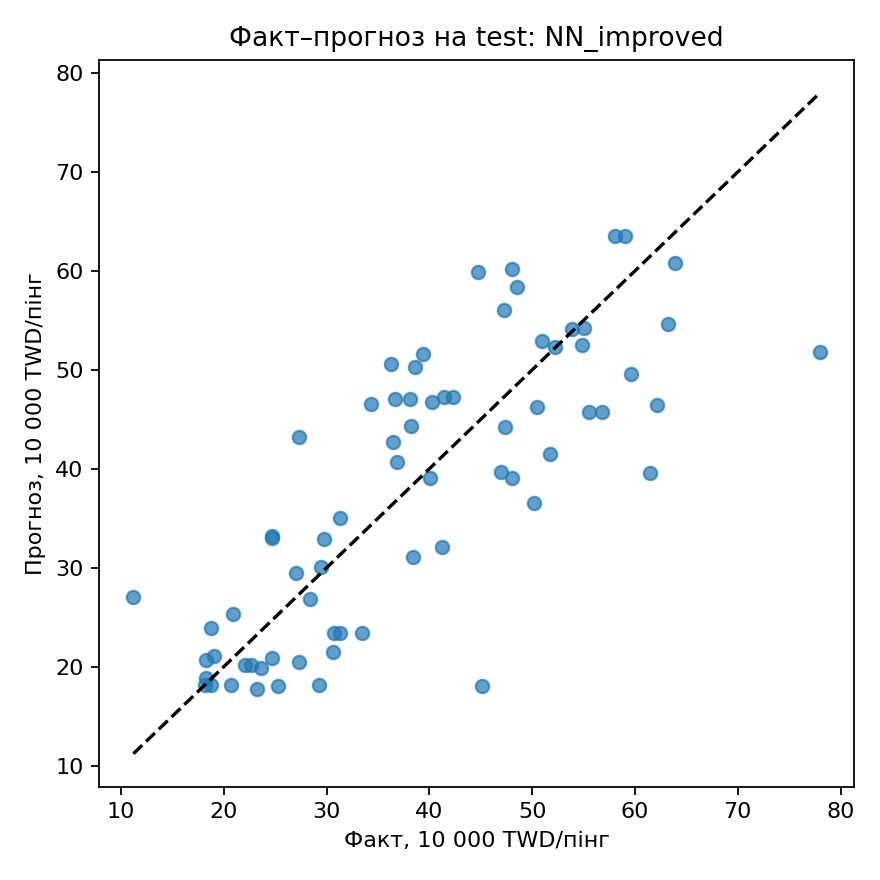

Інтерпретація: відхилення від діагоналі характеризує помилки; test MAE = 7.39 10 000 TWD/пінг.


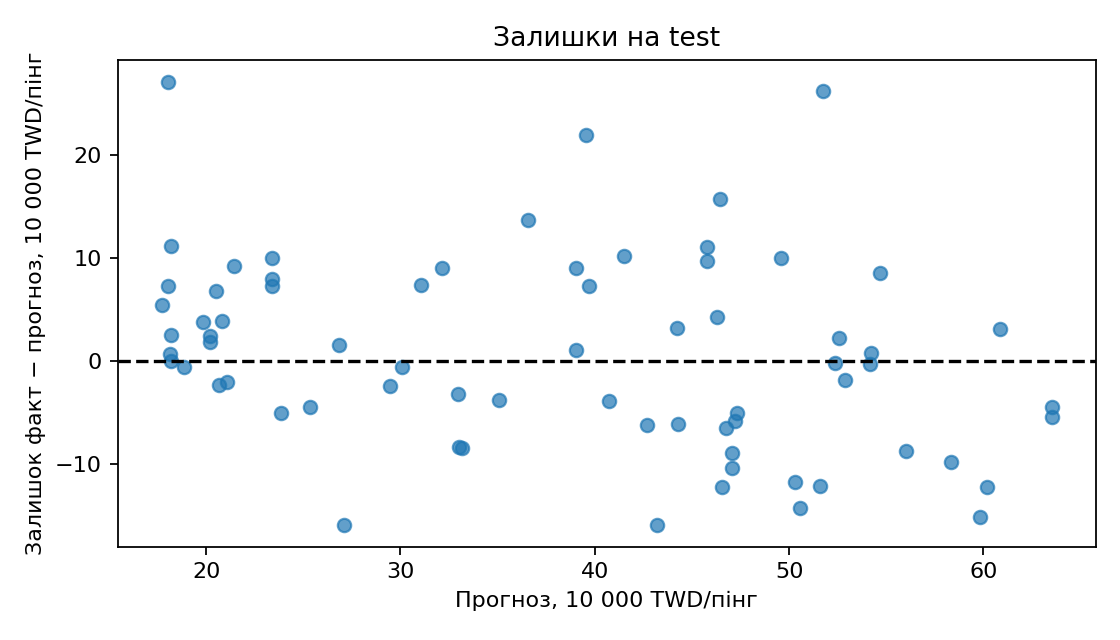

Інтерпретація: додатний залишок означає недооцінку; найбільша абсолютна помилка = 27.08 10 000 TWD/пінг.


In [8]:
UNIT = '10 000 TWD/пінг'
plt.figure(figsize=(7,4))
plt.hist(y_train, bins=20, edgecolor='white')
plt.xlabel(f'Ціна за одиницю площі, {UNIT}'); plt.ylabel('Кількість угод у train')
plt.title('Розподіл цілі у train'); plt.tight_layout()
plt.savefig(FIG/'target_train.png', dpi=160); plt.close(); display(Image(filename=str(FIG/'target_train.png')))
print('Інтерпретація: більшість train-угод зосереджена в центральному діапазоні ціни; крайні значення трапляються рідше.')

fig, ax = plt.subplots(figsize=(8,4.5))
for name, hist, ep, color in [('NN_base',hist_base,epoch_base,'tab:blue'),
                               ('NN_improved',hist_improved,epoch_improved,'tab:orange')]:
    ax.plot(np.sqrt(hist['loss']), color=color, alpha=.45, label=f'{name} train')
    ax.plot(np.sqrt(hist['val_loss']), color=color, label=f'{name} validation')
    ax.axvline(ep-1, color=color, linestyle=':', alpha=.8)
ax.set(xlabel='Епоха', ylabel=f'RMSE, {UNIT}', title='Криві навчання; пунктир — checkpoint')
ax.legend(ncol=2, fontsize=8); fig.tight_layout(); fig.savefig(FIG/'training_curves.png', dpi=160); plt.close(fig); display(Image(filename=str(FIG/'training_curves.png')))
print(f'Інтерпретація: checkpoint base — епоха {epoch_base}, improved — {epoch_improved}; '
      f'validation RMSE {validation.loc["NN_base","RMSE"]:.2f} → {validation.loc["NN_improved","RMSE"]:.2f}.')

chosen = test_predictions[best_nn_name]
lo = min(y_test.min(),chosen.min()); hi = max(y_test.max(),chosen.max())
fig, ax = plt.subplots(figsize=(5.5,5.5))
ax.scatter(y_test,chosen,alpha=.7); ax.plot([lo,hi],[lo,hi],'k--')
ax.set(xlabel=f'Факт, {UNIT}',ylabel=f'Прогноз, {UNIT}',title=f'Факт–прогноз на test: {best_nn_name}')
fig.tight_layout(); fig.savefig(FIG/'actual_vs_predicted.png',dpi=160); plt.close(fig); display(Image(filename=str(FIG/'actual_vs_predicted.png')))
print(f'Інтерпретація: відхилення від діагоналі характеризує помилки; test MAE = {comparison.loc[best_nn_name,"test_MAE"]:.2f} {UNIT}.')

residual = y_test-chosen
fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(chosen,residual,alpha=.7); ax.axhline(0,color='k',linestyle='--')
ax.set(xlabel=f'Прогноз, {UNIT}',ylabel=f'Залишок факт − прогноз, {UNIT}',title='Залишки на test')
fig.tight_layout(); fig.savefig(FIG/'residuals.png',dpi=160); plt.close(fig); display(Image(filename=str(FIG/'residuals.png')))
print(f'Інтерпретація: додатний залишок означає недооцінку; найбільша абсолютна помилка = {np.abs(residual).max():.2f} {UNIT}.')

## Конкретні найбільші помилки

Показано до п'яти test-угод із найбільшим абсолютним залишком. Це діагностика обмежень моделі; ці рядки не вилучалися й не впливали на вибір архітектури.

In [9]:
worst = pred_table.copy()
worst['absolute_error'] = worst['residual_selected_nn'].abs()
display(worst.nlargest(5,'absolute_error')[['source_index',ID]+FEATURES+[TARGET,
           f'prediction_{best_nn_name}','residual_selected_nn','absolute_error']])

,source_index,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area,prediction_NN_improved,residual_selected_nn,absolute_error
148,148,149,2013.500000,16.4,3780.5900,0,24.93293,121.51203,45.1,18.024057,27.075943,27.075943
312,312,313,2013.583333,35.4,318.5292,9,24.97071,121.54069,78.0,51.762539,26.237461,26.237461
47,47,48,2013.583333,35.9,640.7391,3,24.97563,121.53715,61.5,39.536167,21.963833,21.963833
35,35,36,2013.500000,13.9,4079.4180,0,25.01459,121.51816,27.3,43.180538,-15.880538,15.880538
347,347,348,2013.583333,17.4,6488.0210,1,24.95719,121.47353,11.2,27.070805,-15.870805,15.870805


## Збереження та перевірка відновлення

Зберігаємо кращу за validation нейромережу, train-препроцесор, метадані та, якщо загалом краща класична модель, її Joblib-файл. Joblib завантажуємо лише з власного довіреного артефакту. На трьох сирих test-рядках порівнюємо повний шлях прогнозування до та після завантаження.

In [10]:
selected_nn = models[best_nn_name]
selected_nn.save(ART/'lab8_model.keras')
joblib.dump(preprocessor, ART/'preprocessor.joblib')
if best_overall in ('Dummy','LinearRegression'):
    joblib.dump(models[best_overall], ART/'best_classical.joblib')
metadata = {
    'variant': 5, 'list_number': 17, 'source': 'UCI Real Estate Valuation',
    'source_url': 'https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set',
    'citation_doi': '10.24432/C5J30W', 'license': 'CC BY 4.0',
    'download_date': '2026-11-09', 'file': str(DATA), 'sheet': SHEET,
    'target': TARGET, 'target_units': UNIT, 'task_type': 'regression',
    'feature_order': FEATURES, 'numeric_features': NUMERIC, 'categorical_features': CATEGORICAL,
    'class_order': None, 'positive_class': None, 'seed': SEED,
    'split_indices': {k: v.tolist() for k,v in splits.items()},
    'split_policy': 'chronological; equal transaction dates stay together',
    'change': 'Adam learning rate 0.001 -> 0.0003',
    'selected_nn': best_nn_name, 'selected_overall': best_overall,
    'versions': VERSIONS
}
(ROOT/'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
raw_three = X_test.iloc[:3].copy()
before = selected_nn.predict(preprocessor.transform(raw_three).astype('float32'),verbose=0)
loaded_meta = json.loads((ROOT/'metadata.json').read_text(encoding='utf-8'))
loaded_preprocessor = joblib.load(ART/'preprocessor.joblib')
loaded_nn = keras.models.load_model(ART/'lab8_model.keras')
after = loaded_nn.predict(loaded_preprocessor.transform(raw_three[loaded_meta['feature_order']]).astype('float32'),verbose=0)
np.testing.assert_allclose(before,after,rtol=1e-5,atol=1e-6)
print('Відновлення всього комплекту підтверджено на 3 сирих рядках.')
display(pd.DataFrame({'before':before.ravel(),'after':after.ravel()}))

Відновлення всього комплекту підтверджено на 3 сирих рядках.


,before,after
0,52.551807,52.551807
1,23.869005,23.869005
2,46.525700,46.525700


## Висновок

Наведені нижче числа обчислюються з результатів цього запуску. Validation використовувалася для вибору, test — лише для фінальної оцінки.

In [11]:
change = validation.loc['NN_improved','RMSE']-validation.loc['NN_base','RMSE']
effect = 'покращило' if change < 0 else ('не змінило' if change == 0 else 'погіршило')
dummy_rmse = comparison.loc['Dummy','test_RMSE']
linear_rmse = comparison.loc['LinearRegression','test_RMSE']
nn_rmse = comparison.loc[best_nn_name,'test_RMSE']
sentences = [
 f'Розв’язано задачу регресії: за шістьма ознаками угоди прогнозується ціна за одиницю площі в 10 000 TWD/пінг.',
 f'У джерелі {len(df)} записів, пропусків і точних дублікатів без No немає; No виключено як ідентифікатор.',
 f'Хронологічний поділ за датою без розриву однакових дат дав {len(idx_train)}/{len(idx_val)}/{len(idx_test)} записів у train/validation/test.',
 f'На test RMSE обраної мережі {nn_rmse:.2f}, Dummy {dummy_rmse:.2f}, LinearRegression {linear_rmse:.2f} 10 000 TWD/пінг.',
 f'Зменшення learning rate до 0.0003 {effect} validation RMSE на {abs(change):.2f}; обрана мережа — {best_nn_name}.',
 f'Її test MAE дорівнює {comparison.loc[best_nn_name,"test_MAE"]:.2f}, RMSE {nn_rmse:.2f}, R² {comparison.loc[best_nn_name,"test_R2"]:.3f}.',
 f'Найбільша абсолютна test-помилка становить {np.abs(residual).max():.2f} 10 000 TWD/пінг; конкретні угоди наведено вище.',
 'Дані охоплюють один район і короткий часовий проміжок, тому результат на цьому поділі не гарантує точності в інших районах або пізніших умовах ринку.'
]
for s in sentences: print('•',s)

• Розв’язано задачу регресії: за шістьма ознаками угоди прогнозується ціна за одиницю площі в 10 000 TWD/пінг.
• У джерелі 414 записів, пропусків і точних дублікатів без No немає; No виключено як ідентифікатор.
• Хронологічний поділ за датою без розриву однакових дат дав 286/58/70 записів у train/validation/test.
• На test RMSE обраної мережі 9.33, Dummy 14.40, LinearRegression 9.49 10 000 TWD/пінг.
• Зменшення learning rate до 0.0003 покращило validation RMSE на 0.15; обрана мережа — NN_improved.
• Її test MAE дорівнює 7.39, RMSE 9.33, R² 0.579.
• Найбільша абсолютна test-помилка становить 27.08 10 000 TWD/пінг; конкретні угоди наведено вище.
• Дані охоплюють один район і короткий часовий проміжок, тому результат на цьому поділі не гарантує точності в інших районах або пізніших умовах ринку.
